# Simulation: Source Spike with Propagation

Explain simulation please

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

## 🧠 Data

## ♾️ Loop

# Step Wise Run

Run the code step by step for a single simulation.

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
from pathlib import Path
import scipy as sp
import matplotlib.pyplot as plt

## 🧠 Data

In [2]:
# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][0]

# data
data  = mm.io.read_dataset(sub, "eeg_coreg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx_mask")

# forward matrix
A = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]

# Neighbor regions ?
#vertices  = np.vstack([data["white"][0][0], data["white"][1][0]])
#triangles = np.vstack([data["white"][0][1], data["white"][1][1]+len(data["white"][0][0])])
#neighbors = mm.utils.find_neighbor_regions([vertices, triangles], data["parc"], data["cras"])           # region neighbors

# region label of dipoles
regions = data["parc"].get_clut()["Label name"].values                                                  # region ids
pos     = mm.utils.get_src_position(data["fwd"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)                                                                # dipole labels

# eeg meta-data
sfreq = data["eeg_coreg"].info["sfreq"]
time  = data["eeg_coreg"].times

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- bem
- ctx_mask
- white
- parc
- fwd
- sc
- cras
- cst
- eeg_coreg
Missing objects:


## Visualize Data

#### 🌟 EEG Coregistration

In [3]:
pos_elec  = mm.utils.get_ch_positions(data["eeg_coreg"])
head      = data["bem"][0]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(pos_elec), color="red")
plotter.add_mesh(mm.utils.surf_to_polydata(head["rr"], head["tris"]))
plotter.show()

Widget(value='<iframe src="http://localhost:42733/index.html?ui=P_0x7f5ab7532ba0_0&reconnect=auto" class="pyvi…

#### 🌟 Forward Solution

In [5]:
mm.viz.plot_leadfield(data["eeg_coreg"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:39727/index.html?ui=P_0x756a36b24ef0_1&reconnect=auto" class="pyvi…

#### 🌟 Connectivity

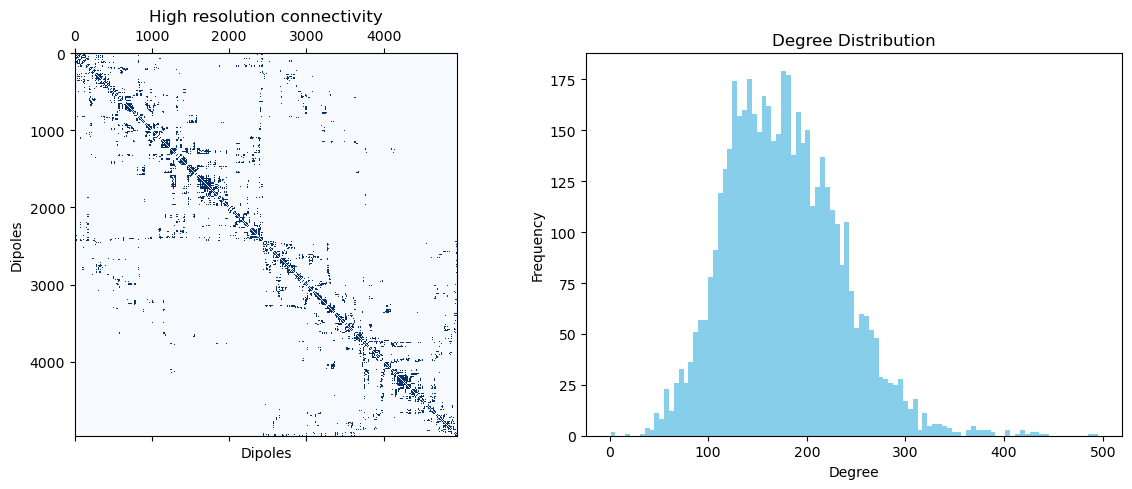

In [6]:
label_ids = data["parc"].label_points(pos, id=True)
indices   = np.argsort(label_ids)

mm.viz.plot_connectome(data["sc"][indices][:,indices], name="High resolution connectivity")

#### 🌟 Connectome spectrum

In [7]:
harmonic = data["cst"][1,:]
max_abs  = np.max(np.abs(harmonic))
mm.viz.plot_brain_signal(data["fwd"]["src"], harmonic, clim=[-max_abs, max_abs]).show()

Widget(value='<iframe src="http://localhost:39727/index.html?ui=P_0x756a12f7c050_2&reconnect=auto" class="pyvi…

#### 🌟 Print list of brain regions

In [8]:
print("\033[94mList of regions: \033[0m")
print(np.unique(labels))

List of regions: 
['ctx-lh-bankssts_1' 'ctx-lh-bankssts_2' 'ctx-lh-bankssts_3'
 'ctx-lh-caudalanteriorcingulate_1' 'ctx-lh-caudalanteriorcingulate_2'
 'ctx-lh-caudalanteriorcingulate_3' 'ctx-lh-caudalmiddlefrontal_1'
 'ctx-lh-caudalmiddlefrontal_2' 'ctx-lh-caudalmiddlefrontal_3'
 'ctx-lh-caudalmiddlefrontal_4' 'ctx-lh-caudalmiddlefrontal_5'
 'ctx-lh-cuneus_1' 'ctx-lh-cuneus_2' 'ctx-lh-cuneus_3' 'ctx-lh-cuneus_4'
 'ctx-lh-entorhinal_1' 'ctx-lh-frontalpole_1' 'ctx-lh-fusiform_1'
 'ctx-lh-fusiform_2' 'ctx-lh-fusiform_3' 'ctx-lh-fusiform_4'
 'ctx-lh-fusiform_5' 'ctx-lh-fusiform_6' 'ctx-lh-fusiform_7'
 'ctx-lh-fusiform_8' 'ctx-lh-inferiorparietal_1'
 'ctx-lh-inferiorparietal_10' 'ctx-lh-inferiorparietal_11'
 'ctx-lh-inferiorparietal_12' 'ctx-lh-inferiorparietal_2'
 'ctx-lh-inferiorparietal_3' 'ctx-lh-inferiorparietal_4'
 'ctx-lh-inferiorparietal_5' 'ctx-lh-inferiorparietal_6'
 'ctx-lh-inferiorparietal_7' 'ctx-lh-inferiorparietal_8'
 'ctx-lh-inferiorparietal_9' 'ctx-lh-inferiortemporal_1'
 '

## Simulation

#### 🛠️ <font color=violet>Source Spike</font>
- `duration`: duration of the simulation
- `stype`: spike type
    - "mex": mexican hat
    - "ham": double ham
- `amplitude`: maximum amplitude of spike
- `width`: duration of the spike
- `location`: location of the source spike given by a brain region

In [3]:
# parameters
duration  = 1
stype     = "mex"
amplitude = 1e-8
width     = None
location  = "random"

#### 🛠️ <font color=violet>Spike Propagation</font>
- `dw`: Propagation weight [0-1]
- `dt`: Propagation delay in [ms]

In [4]:
# parameters
dw = 0.25 
dt = 50

#### 🛠️ <font color=violet>Noise Generation</font>
- `target_snr`: Maximum EEG SNR in [dB] expcted
- `ratio`: Ratio [0-1] between brain noise and EEG electrical noise.

In [27]:
# parameters
target_snr = 10
ratio      = 0.9

#### ⚙️ **<font color=green>Generate simulation</fon>**

In [28]:
spike          = mm.utils.create_source_spike(duration, sfreq, stype, amplitude)
spike_activity = mm.utils.generate_spike_activity(data["fwd"]["src"], data["sc"], data["parc"], spike, dw=dw, dt=dt, sfreq=sfreq, cras=data["cras"])

brain_noise, eeg_noise = mm.utils.generate_scaled_noise(spike_activity, data["fwd"], target_snr, ratio, bn_type="pink")
brain, eeg             = mm.utils.simulate_eeg(spike_activity, data["fwd"], data["eeg_coreg"], brain_noise, eeg_noise, sub)

#### 🌟 Visualize Time Series

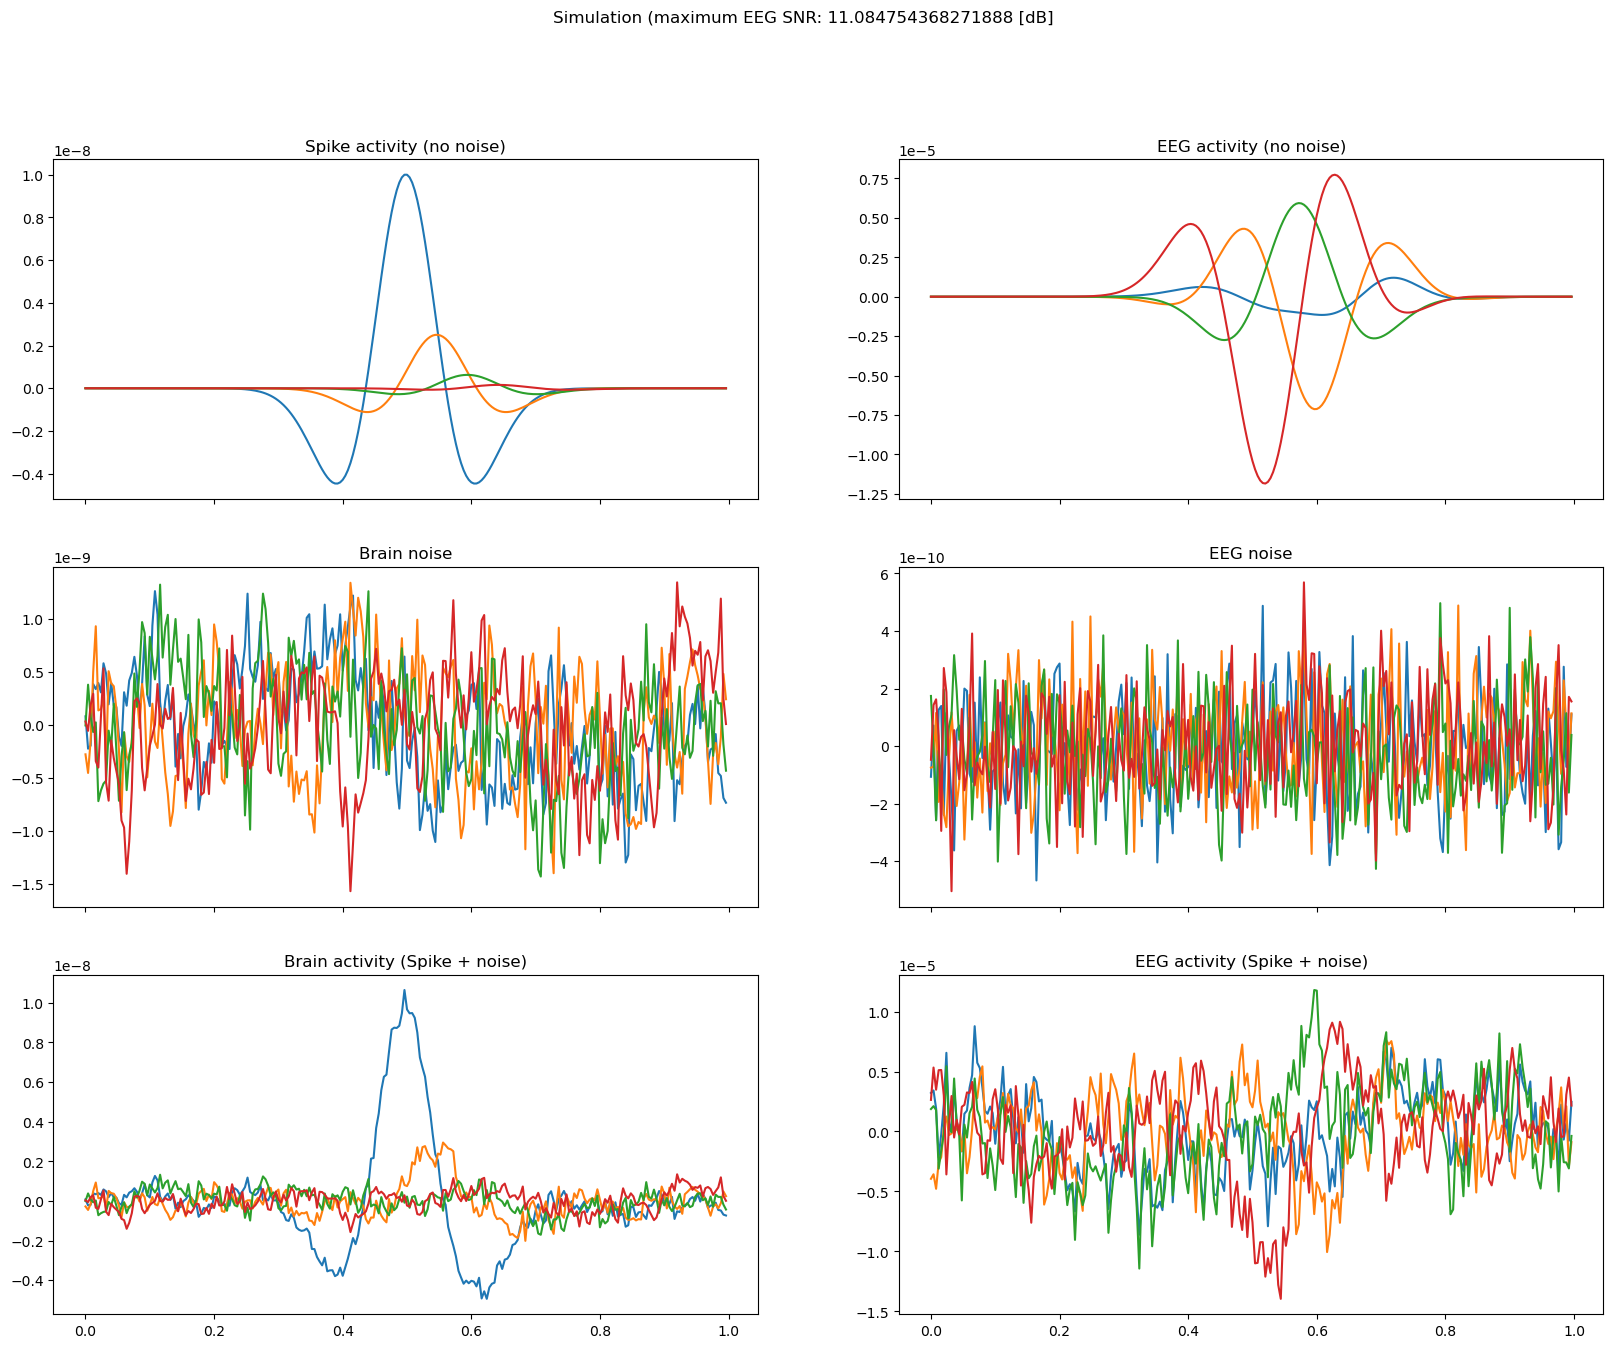

In [30]:
# function to select source, 1hop, 2hop ... 
peak_times = np.argmax(spike_activity, axis=1)
times      = np.unique(peak_times)

idx_brain = lambda i: np.argwhere(peak_times==times[i]).squeeze()[0]       # id of source (i=0), 1hop (i=1), 2hop (i=2) ...

# eeg without noise
_, eeg_clean = mm.utils.simulate_eeg(spike_activity, data["fwd"], data["eeg_coreg"], brain_noise=None, eeg_noise=None)
eeg_max = np.argsort(np.max(eeg_clean.data, axis=1))
idx_eeg = lambda i: eeg_max[30*i]

# compute SNR
Pspike = mm.utils.avg_power(A@spike_activity)
Pbrain = mm.utils.avg_power(A@brain_noise)
Peeg   = mm.utils.avg_power(eeg_noise)
SNR    = 10*np.log10(Pspike/(Pbrain+Peeg))

# plot figures
fig, axes = plt.subplots(3, 2, sharex=True, figsize=(20,15))
fig.suptitle(f"Simulation (maximum EEG SNR: {np.max(SNR):01} [dB]")

axes[0][0].set_title("Spike activity (no noise)")
for i in range(4):
    sns.lineplot(ax=axes[0][0], x=time, y=spike_activity[idx_brain(i),:])

axes[0][1].set_title("EEG activity (no noise)")
for i in range(4):
    sns.lineplot(ax=axes[0][1], x=time, y=eeg_clean.data[idx_eeg(i),:])

axes[1][0].set_title("Brain noise")
for i in range(4):
    sns.lineplot(ax=axes[1][0], x=time, y=brain_noise[idx_brain(i),:])

axes[1][1].set_title("EEG noise")
for i in range(4):
    sns.lineplot(ax=axes[1][1], x=time, y=eeg_noise[idx_eeg(i),:])

axes[2][0].set_title("Brain activity (Spike + noise)")
for i in range(4):
    sns.lineplot(ax=axes[2][0], x=time, y=brain.data[idx_brain(i),:])

axes[2][1].set_title("EEG activity (Spike + noise)")
for i in range(4):
    sns.lineplot(ax=axes[2][1], x=time, y=eeg.data[idx_eeg(i),:])


#### 🌟 Visualize Brain Activity

In [31]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], brain.data)

Widget(value='<iframe src="http://localhost:33721/index.html?ui=P_0x700cc54795b0_13&reconnect=auto" class="pyv…

#### 🌟 Visualize background spectrum

In [32]:
spectrum = data["cst"] @ activity.data
mm.viz.plot_spectrum(spectrum[:, int(spectrum.shape[1]/2)])

#### 🌟 Visualize EEG Activity

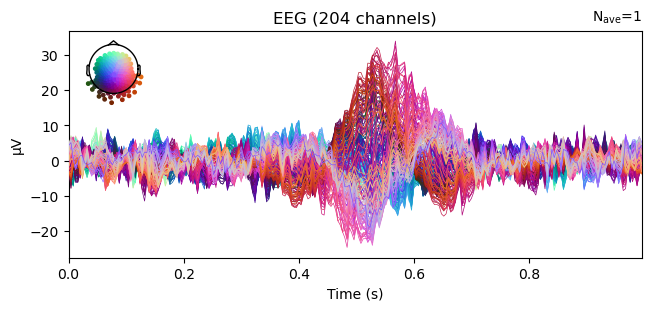

In [33]:
_ = eeg.plot()

# 

#### 🌟 Visualize EEG Topography

In [ ]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(snr)}")
print(f"Maximum SNR: {np.max(snr)}")
_ = mne.viz.plot_topomap(snr, data["eeg_coreg"].info, size=6, outlines=None, extrapolate="local")

In [63]:
# storage
target_snr = np.zeros(rep)                                     
true_snr   = np.zeros((rep, len(data["eeg_coreg"].ch_names)))

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# dipole distance matrix (to grow dipole patch)
dist = [
    data["fwd_hr"]["src"][0]["dist"][vertno[0]][:,vertno[0]], 
    data["fwd_hr"]["src"][1]["dist"][vertno[1]][:,vertno[1]],
]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*1e-8    # scale to nA

# covariance for background dipoles
I    = np.eye(len(data["sc_hr"]))
covb = np.linalg.inv((I-data["sc_hr"])) @ (I-data["sc_hr"])
covb = (covb + covb.T)/2

# estimated EEG average power originating from background dipoles
Pb   = np.diagonal(A @ covb @ A.T)

# functions to compute average power of EEGa and estimate variance
compute_Pa  = lambda Xa: np.diagonal(A @ np.cov(Xa) @ A.T)
compute_var = lambda snr, Pa, Pb: 10**(-snr/10) * Pa/Pb

#### ⚙️ **<font color=green>Loop through simulations</font>**

In [ ]:
for i in range(rep):
    # select state
    snr = np.random.uniform(rg_snr[0], rg_snr[1])
    r   = np.random.uniform(rg_r[0], rg_r[1])

    # generate patch
    starting_roi = np.random.choice(labels)
    roi_mask     = np.isin(labels, starting_roi)
    
    # active dipoles
    Xa = spread_signal(signal, roi_mask, data["sc_hr"], r)
    Pa = compute_Pa(Xa)

    # background dipoles
    idx = np.argmax(Pa)
    var = compute_var(snr, Pa[idx], Pb[idx])

    rng = np.random.default_rng()
    Xb  = rng.multivariate_normal(mean=np.zeros(len(covb)), cov=var*covb, size=int(sfreq*duration), method="cholesky").T

    # EEG SNR
    EEGa    = A @ Xa 
    EEGb    = A @ Xb 
    eeg_snr = mm.utils.compute_snr(EEGa, EEGb)

    # store variance and EEG SNR
    target_snr[i] = snr
    true_snr[i,:] = eeg_snr

#### 🌟 Visualize distributions

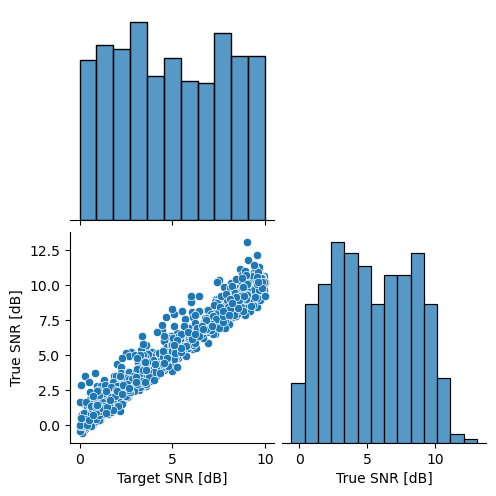

In [115]:
true_snr_max = np.max(true_snr, axis=1)
results      = pd.DataFrame({"True SNR [dB]":true_snr_max, "Target SNR [dB]":target_snr})

_  = sns.pairplot(
    results, 
    x_vars = ["Target SNR [dB]", "True SNR [dB]"],
    y_vars = ["Target SNR [dB]","True SNR [dB]"],
    corner = True,
)

## Section 3: Create Dataset
🚨 Run cell '📦 imports' and '🧠 data' before continuing.

#### Dataset Propreties

In [6]:
# data info
name      = "SNR 20, spreading 25%"                                   # name of dataset
folder    = Path(config["SIM_DIR"])/"sim-SNR20-spw25SAVEME"    # folder to save data
n_samples = 20                                                        # number of samples

# sample properties
#snr_range = [10,11]     # range for the EEG SNR
#spw_range = [0,0.25]    # range for spreading weight
spd       = 50          # spreading delay [ms]
duration  = 1           # duration in [s]
#noise_std = 1e-6
#brw_step  = 1e-10

#### Preparations ...

In [8]:
# check folder existence
if folder.exists():
    raise FileExistsError(f"\033[91mFolder '{folder}' already exists.")
else:
    folder.mkdir(parents=True)

N = data["fwd"]["nsource"]
M = data["eeg_coreg"].info["nchan"]
T = int(sfreq*duration)

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=T)

# shift delay
shift = int(spd/1000*sfreq)

# functions to compute average power of EEGa and estimate variance
compute_scaling = lambda snr, Ps, Pn: np.sqrt(10**(snr/10) * Pn / Ps)

# source locations
source_regions = mm.utils.select_sources(sub, mask=data["ctx_mask"], cras=data["cras"])
source_regions = data["parc"].label_points(source_regions)
source_regions = np.random.choice(source_regions, n_samples)

#### ⚙️ <font color=green>Generate dataset</font>

In [9]:
folder = Path(folder)

for i in range(n_samples):

    # select state
    snr      = 20
    r        = source_regions[i]

    eeg, gt, _, _ = mm.utils.simulate_EEG(data["eeg_coreg"].info, data["fwd"], labels, data["sc"], r, target_snr=snr, electric_noise=1e-9)

    # save simulation
    fsample = folder/f"sample{i+1}"
    fsample.mkdir()

    gt[0].save(fsample/f"{sub}_sample{i+1}_stc.fif", verbose="warning")
    eeg[0].save(fsample/f"{sub}_sample{i+1}_ave.fif", verbose="warning")


# create info file
text = f"""
    Name: {name} \n
    Subject: {sub} \n
    Duration: {duration} seconds [s]\n
    Sampling frequency: {sfreq} [Hz]\n
    """

with open(folder/"info.txt", "w") as file:
    file.write(text)